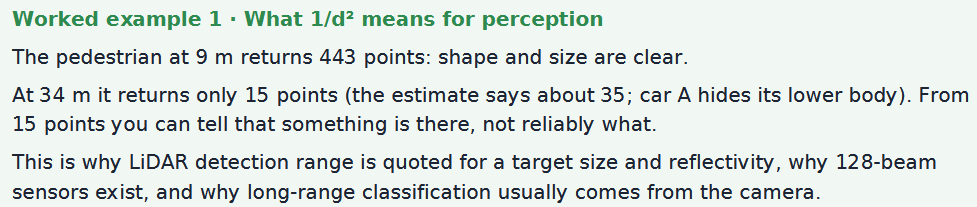

In [1]:
import sys; sys.path.insert(0, "..")          # the notebook runs inside notebooks/
import numpy as np
from src import scene
from src.pointcloud import points_on_target

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)

# 1. rule of thumb vs. simulated scan
print("distance   estimate   simulated")
for lab, dist in [(20, 9), (21, 34)]:
    rows, cols, n = points_on_target(height=1.75, width=0.6, distance=dist)
    print(f"{dist:5d} m   {n:7.0f}    {np.sum(labels == lab):8d}   "
          f"({rows:.1f} beams x {cols:.1f} columns)")

# 2. how much does car A hide? run the same scan without car A
boxes_saved = list(scene.BOXES)
scene.BOXES[:] = [b for b in scene.BOXES if b[0] != 10]      # remove car A (label 10)
_, labels_free, _ = scene.simulate_scan(np.random.default_rng(0))
scene.BOXES[:] = boxes_saved                                  # put it back
print(f"\npedestrian at 34 m without car A in front: {np.sum(labels_free == 21)} points")

# 3. the 1/d^2 law
for d in [10, 20, 40, 80]:
    print(f"pedestrian at {d:2d} m: ~{points_on_target(1.75, 0.6, d)[2]:5.0f} points")

distance   estimate   simulated
    9 m       495         443   (25.9 beams x 19.1 columns)
   34 m        35          15   (6.9 beams x 5.1 columns)

pedestrian at 34 m without car A in front: 34 points
pedestrian at 10 m: ~  401 points
pedestrian at 20 m: ~  100 points
pedestrian at 40 m: ~   25 points
pedestrian at 80 m: ~    6 points


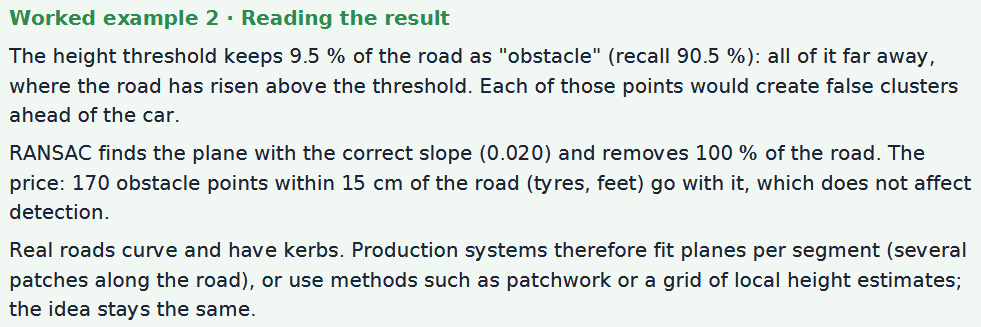

height threshold  recall  90.5%  precision 100.0%  obstacle points removed 0
RANSAC plane      recall 100.0%  precision  99.6%  obstacle points removed 170
RANSAC slope 0.020 (true 0.02), height at the sensor -1.73 m (true -1.73)

road points the threshold calls 'obstacle': 3671, from x = 9.6 m to 46.7 m
expected: the road rises 0.2 m above the sensor's ground level at x = 10 m
obstacle points removed by RANSAC: 170, all lower than 16 cm


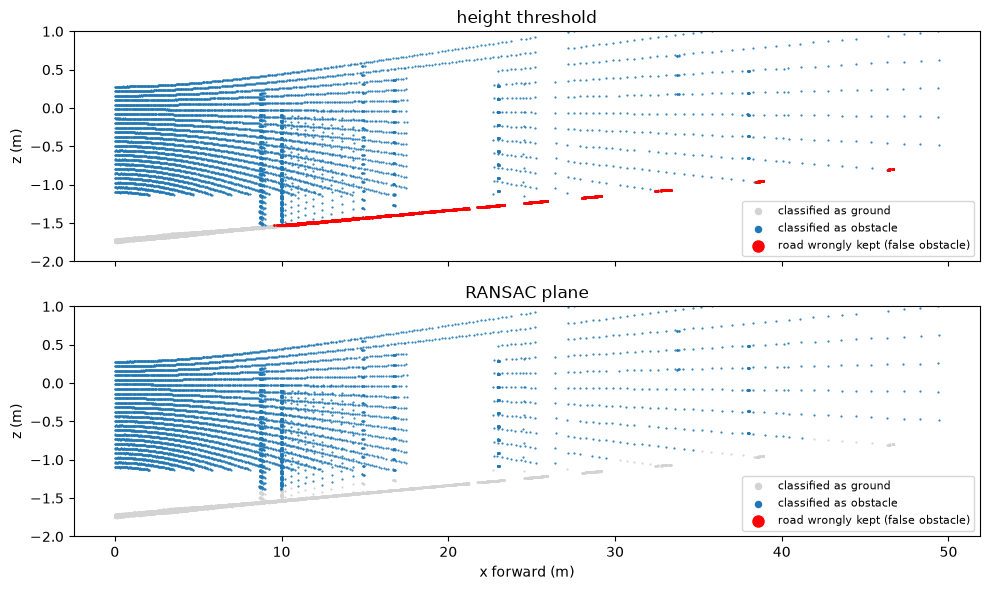

In [2]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src import scene
from src.pointcloud import crop, ransac_plane

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)
roi, roi_mask = crop(cloud)                      # 0-50 m ahead, +-10 m to the side
p = roi[:, :3]
is_ground = labels[roi_mask] == 1                # ground truth from the simulation

# two ground classifiers
ground_naive = p[:, 2] < -scene.SENSOR_HEIGHT + 0.2       # "everything low is ground"
n, d, ground_ransac = ransac_plane(p, threshold=0.15)

def report(name, pred):
    tp = np.sum(pred & is_ground)
    print(f"{name:17s} recall {tp / is_ground.sum():6.1%}  precision {tp / pred.sum():6.1%}  "
          f"obstacle points removed {np.sum(pred & ~is_ground)}")

report("height threshold", ground_naive)
report("RANSAC plane", ground_ransac)
print(f"RANSAC slope {-n[0] / n[2]:.3f} (true {scene.SLOPE}), "
      f"height at the sensor {-d / n[2]:.2f} m (true {-scene.SENSOR_HEIGHT})")

# where does the threshold fail?
missed = is_ground & ~ground_naive
print(f"\nroad points the threshold calls 'obstacle': {missed.sum()}, "
      f"from x = {p[missed, 0].min():.1f} m to {p[missed, 0].max():.1f} m")
x_fail = 0.2 / scene.SLOPE
print(f"expected: the road rises 0.2 m above the sensor's ground level at x = {x_fail:.0f} m")

# which obstacle points does RANSAC remove?
lost = ground_ransac & ~is_ground
h = p[lost, 2] - scene.ground_z(p[lost, 0])
print(f"obstacle points removed by RANSAC: {lost.sum()}, all lower than {h.max() * 100:.0f} cm")

# side view
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a, pred, title in [(ax[0], ground_naive, "height threshold"),
                       (ax[1], ground_ransac, "RANSAC plane")]:
    a.scatter(p[pred, 0], p[pred, 2], s=0.3, c="lightgrey", label="classified as ground")
    a.scatter(p[~pred, 0], p[~pred, 2], s=0.3, c="tab:blue", label="classified as obstacle")
    a.scatter(p[~pred & is_ground, 0], p[~pred & is_ground, 2], s=1, c="red",
              label="road wrongly kept (false obstacle)")
    a.set_ylim(-2, 1); a.set_ylabel("z (m)"); a.set_title(title)
    a.legend(markerscale=8, fontsize=8)
ax[1].set_xlabel("x forward (m)")
plt.tight_layout(); plt.show()

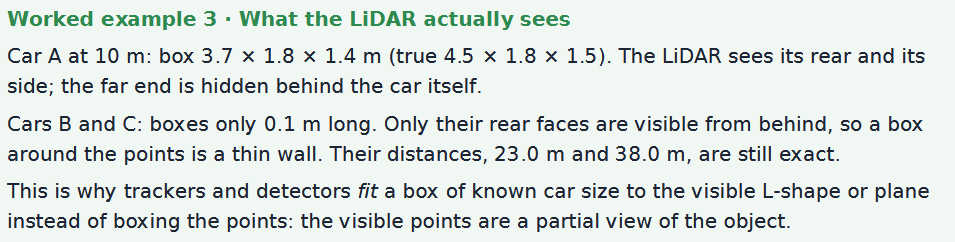

car    points   box around points (L x W x H)  IoU points-box  IoU fitted box
car A    1008        3.7 x 1.8 x 1.4 m (true 4.5 x 1.8)            0.80            0.97   closest 10.0 m
car B     200        0.1 x 1.8 x 1.4 m (true 4.5 x 1.8)            0.01            0.98   closest 23.0 m
car C      67        0.1 x 1.7 x 1.1 m (true 4.6 x 1.9)            0.01            0.90   closest 38.0 m


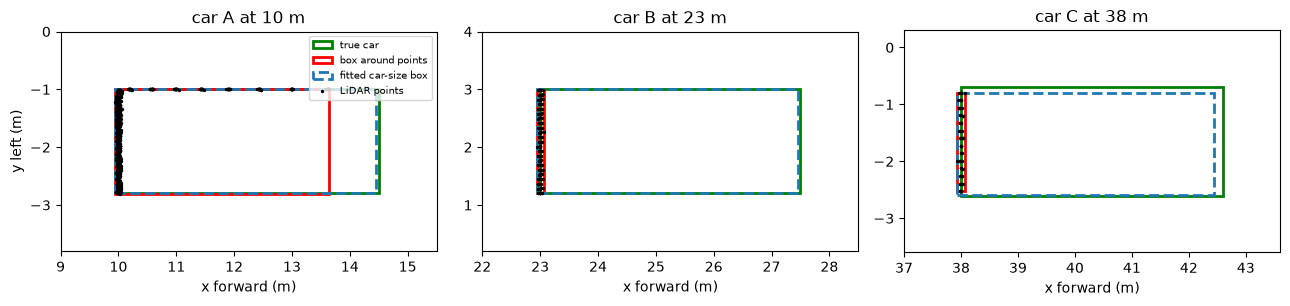

In [3]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src import scene
from src.pointcloud import crop, ransac_plane, euclidean_clusters, cluster_box

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)
roi, roi_mask = crop(cloud)
p, roi_labels = roi[:, :3], labels[roi_mask]
n, d, ground = ransac_plane(p)
obst, obst_true = p[~ground], roi_labels[~ground]
lab = euclidean_clusters(obst)                       # cluster id per obstacle point

# ground-truth car boxes: label -> (x_min, x_max, y_min, y_max, height)
TRUE = {b[0]: b[1:] for b in scene.BOXES}

def bev_iou(a, b):
    """IoU of two axis-aligned boxes (x_min, x_max, y_min, y_max) seen from above."""
    w = max(0, min(a[1], b[1]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[2], b[2]))
    inter = w * h
    area = lambda r: (r[1] - r[0]) * (r[3] - r[2])
    return inter / (area(a) + area(b) - inter)

def fit_car_box(pts, length=4.5, width=1.8):
    """Place a box of known car size at the visible corner closest to the sensor:
    the rear face is the nearest x, the visible side is the y edge closest to y = 0."""
    x0 = pts[:, 0].min()
    if pts[:, 1].mean() < 0:                         # car on the right: visible side at y max
        y1 = pts[:, 1].max()
        return (x0, x0 + length, y1 - width, y1)
    y0 = pts[:, 1].min()                             # car on the left: visible side at y min
    return (x0, x0 + length, y0, y0 + width)

print(f"{'car':6s} {'points':>6s}  {'box around points (L x W x H)':>30s}  "
      f"{'IoU points-box':>14s}  {'IoU fitted box':>14s}")
for car in (10, 11, 12):
    c = np.bincount(lab[obst_true == car][lab[obst_true == car] >= 0]).argmax()
    pts = obst[lab == c]
    lo, hi, closest = cluster_box(pts)
    size = hi - lo
    raw = (lo[0], hi[0], lo[1], hi[1])
    fitted = fit_car_box(pts)
    t = TRUE[car][:4]
    print(f"{scene.NAMES[car]:6s} {len(pts):6d}  {size[0]:9.1f} x {size[1]:3.1f} x {size[2]:3.1f} m "
          f"(true {t[1] - t[0]:.1f} x {t[3] - t[2]:.1f})"
          f"  {bev_iou(raw, t):14.2f}  {bev_iou(fitted, t):14.2f}   closest {closest:.1f} m")

# bird's-eye view of the three cars
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, car in zip(axs, (10, 11, 12)):
    c = np.bincount(lab[obst_true == car][lab[obst_true == car] >= 0]).argmax()
    pts = obst[lab == c]
    lo, hi, _ = cluster_box(pts)
    t = TRUE[car][:4]
    f = fit_car_box(pts)
    for (x0, x1, y0, y1), col, name in [(t, "green", "true car"),
                                        ((lo[0], hi[0], lo[1], hi[1]), "red", "box around points"),
                                        (f, "tab:blue", "fitted car-size box")]:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2,
                                   ls="--" if col == "tab:blue" else "-", label=name))
    ax.scatter(pts[:, 0], pts[:, 1], s=2, c="k", label="LiDAR points")
    ax.set_xlim(t[0] - 1, t[1] + 1); ax.set_ylim(t[2] - 1, t[3] + 1); ax.set_aspect("equal")
    ax.set_title(f"{scene.NAMES[car]} at {t[0]:.0f} m"); ax.set_xlabel("x forward (m)")
axs[0].set_ylabel("y left (m)"); axs[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

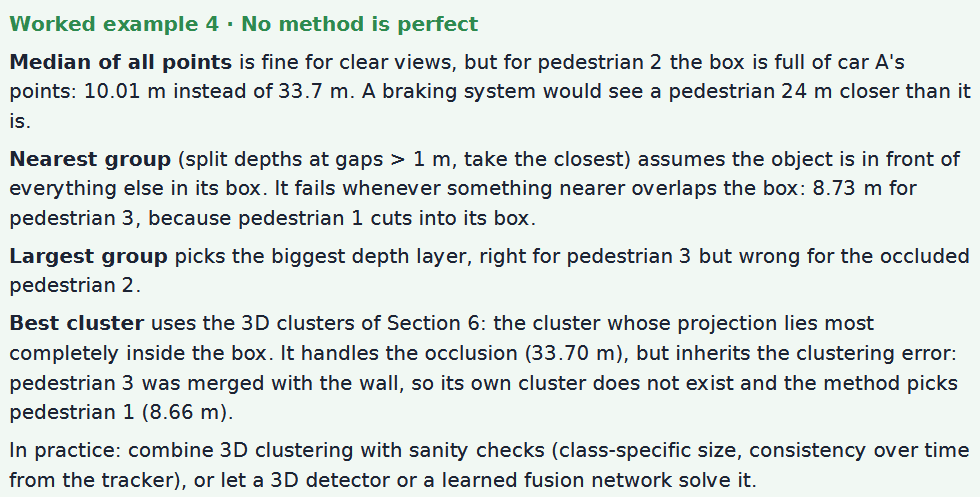

object         true         median  nearest group  largest group   best cluster
car A          10.0          10.01          10.00          10.00           9.95
car B          23.0          23.00          23.00          23.00          22.95
car C          38.0          38.01          38.00          38.00          37.93
pedestrian 1    8.7           8.82           8.75           8.75           8.66
pedestrian 2   33.7          10.01          10.00          10.00          33.70
pedestrian 3   16.7          16.70           8.73          16.78           8.66

points in the box of pedestrian 2 (ground removed): {'car A': 35, 'pedestrian 2': 15}

points in the box of pedestrian 3 (ground removed): {'wall': 45, 'pedestrian 1': 95, 'pedestrian 3': 82}


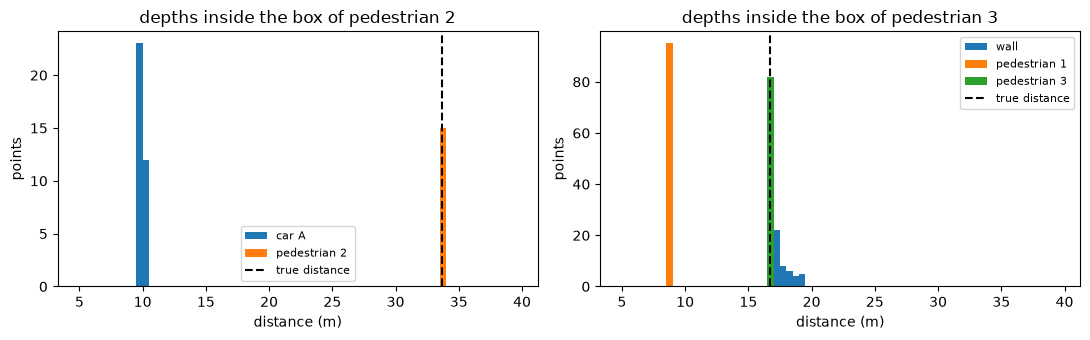

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src import scene
from src.pointcloud import crop, ransac_plane, euclidean_clusters
from src.projection import project_lidar_to_image
from src.fusion import box_distance, METHODS

# ---------- LiDAR pipeline (as in the earlier examples) ----------
rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)
roi, roi_mask = crop(cloud)
p = roi[:, :3]
n, d, ground_roi = ransac_plane(p)
lab_kd = euclidean_clusters(p[~ground_roi])

# ---------- camera and detector boxes ----------
T = scene.camera_extrinsics()
label_image = scene.render_label_image()
detections = scene.simulate_detections(label_image, T, rng)   # [(true label, box), ...]

# per-point information on the FULL cloud, needed by box_distance
ground_all = np.abs(points @ n + d) < 0.15                    # ground mask
cluster_id = np.full(len(points), -1)                         # cluster id (-1 = none)
cluster_id[np.nonzero(roi_mask)[0][~ground_roi]] = lab_kd
kw = dict(points=points, T_cam_lidar=T, K=scene.K, width=scene.W_IMG, height=scene.H_IMG,
          ground_mask=ground_all, cluster_id=cluster_id, cam_x=scene.CAM_POS[0])

print(f"{'object':13s} {'true':>5s}" + "".join(f"{m:>15s}" for m in METHODS))
for lab, box in detections:
    est = [box_distance(box, m, **kw) for m in METHODS]
    print(f"{scene.NAMES[lab]:13s} {scene.TRUE_DIST[lab]:5.1f}"
          + "".join(f"{e:15.2f}" for e in est))

# ---------- look inside the two difficult boxes ----------
uv, depth, idx = project_lidar_to_image(points, T, scene.K, scene.W_IMG, scene.H_IMG)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, target in zip(axs, (21, 22)):
    box = dict(detections)[target]
    inb = ((uv[:, 0] >= box[0]) & (uv[:, 0] <= box[2]) & (uv[:, 1] >= box[1]) & (uv[:, 1] <= box[3])
           & ~ground_all[idx])
    who = labels[idx[inb]]
    print(f"\npoints in the box of {scene.NAMES[target]} (ground removed):",
          {scene.NAMES.get(l, l): int(np.sum(who == l)) for l in np.unique(who)})
    for l in np.unique(who):
        ax.hist(depth[inb][who == l] + scene.CAM_POS[0], bins=np.arange(5, 40, 0.5),
                label=scene.NAMES.get(l, l))
    ax.axvline(scene.TRUE_DIST[target], color="k", ls="--", label="true distance")
    ax.set_title(f"depths inside the box of {scene.NAMES[target]}")
    ax.set_xlabel("distance (m)"); ax.set_ylabel("points"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [2]:
def cluster_scores(box):
    """(fraction of the cluster inside the box, points inside) for every cluster in the box."""
    inb = ((uv[:, 0] >= box[0]) & (uv[:, 0] <= box[2]) & (uv[:, 1] >= box[1]) & (uv[:, 1] <= box[3]))
    ids = cluster_id[idx[inb]]
    return {c: (np.sum(ids == c) / np.sum(cluster_id[idx] == c), np.sum(ids == c))
            for c in np.unique(ids) if c >= 0}

pairs = []                                            # (score, detection index, cluster)
for i, (lab, box) in enumerate(detections):
    for c, s in cluster_scores(box).items():
        pairs.append((s, i, c))

assigned, used = {}, set()
for s, i, c in sorted(pairs, reverse=True):           # best matches first (greedy)
    if i not in assigned and c not in used and s[0] > 0.5:
        assigned[i] = c
        used.add(c)

print(f"{'object':13s} {'true':>5s} {'combined':>9s}  how")
for i, (lab, box) in enumerate(detections):
    if i in assigned:
        est, how = points[cluster_id == assigned[i], 0].min(), "own 3D cluster"
    else:                                             # no free cluster: fall back to depth layers
        est, how = box_distance(box, "largest group", **kw), "fallback: largest depth group"
    print(f"{scene.NAMES[lab]:13s} {scene.TRUE_DIST[lab]:5.1f} {est:9.2f}  {how}")

object         true  combined  how
car A          10.0      9.95  own 3D cluster
car B          23.0     22.95  own 3D cluster
car C          38.0     37.93  own 3D cluster
pedestrian 1    8.7      8.66  own 3D cluster
pedestrian 2   33.7     33.70  own 3D cluster
pedestrian 3   16.7     16.78  fallback: largest depth group


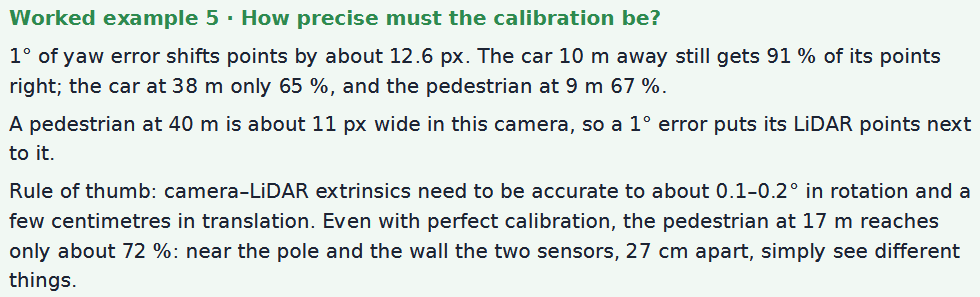

yaw error  shift    car 10 m   car 38 m    ped 9 m   ped 17 m
 0.00 deg   0.0 px     99.9%     100.0%      93.9%      71.9%
 0.10 deg   1.3 px     98.4%      93.1%      93.7%      86.5%
 0.25 deg   3.1 px     96.7%      86.1%      88.0%      73.0%
 0.50 deg   6.3 px     94.9%      79.2%      82.8%      58.4%
 1.00 deg  12.6 px     91.1%      65.3%      66.6%      14.6%
 2.00 deg  25.2 px     82.2%      34.7%      39.1%       0.0%

lateral offset    car 10 m   car 38 m    ped 9 m   ped 17 m
    0 cm            99.9%     100.0%      93.9%      71.9%
    5 cm            98.3%     100.0%      93.9%      70.8%
   10 cm            94.9%     100.0%      83.1%      70.8%

pedestrian (0.6 m) at 10 m:  43.3 px wide,  1 deg shifts 12.6 px,  5 cm offset shifts 3.6 px
pedestrian (0.6 m) at 20 m:  21.6 px wide,  1 deg shifts 12.6 px,  5 cm offset shifts 1.8 px
pedestrian (0.6 m) at 40 m:  10.8 px wide,  1 deg shifts 12.6 px,  5 cm offset shifts 0.9 px


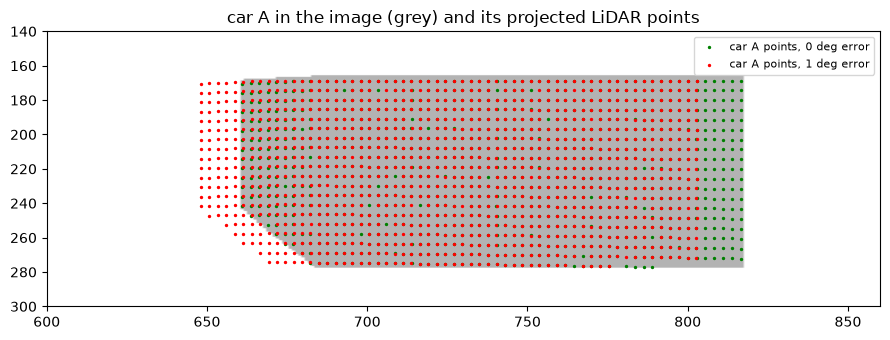

In [3]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src import scene
from src.projection import project_lidar_to_image, rotz

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)
label_image = scene.render_label_image()              # what the camera really sees
T_true = scene.camera_extrinsics()
fx = scene.K[0, 0]

def on_correct_object(T, lab):
    """Share of an object's LiDAR points that land on the same object in the image."""
    uv, _, idx = project_lidar_to_image(points, T, scene.K, scene.W_IMG, scene.H_IMG)
    sel = labels[idx] == lab
    seen = label_image[uv[sel, 1].astype(int), uv[sel, 0].astype(int)]
    return np.mean(seen == lab)

objects = [(10, "car 10 m"), (12, "car 38 m"), (20, "ped 9 m"), (22, "ped 17 m")]

# 1. rotation (yaw) error
print("yaw error  shift   " + "  ".join(f"{name:>9s}" for _, name in objects))
for err in [0.0, 0.1, 0.25, 0.5, 1.0, 2.0]:
    T_bad = T_true.copy()
    T_bad[:3, :3] = scene.R_CAM_LIDAR @ rotz(err)     # camera turned by err degrees
    shares = [on_correct_object(T_bad, lab) for lab, _ in objects]
    print(f"{err:5.2f} deg  {fx * np.tan(np.radians(err)):4.1f} px "
          + "  ".join(f"{s:9.1%}" for s in shares))

# 2. translation error: the camera assumed 5 cm / 10 cm too far to the left
print("\nlateral offset   " + "  ".join(f"{name:>9s}" for _, name in objects))
for off in [0.0, 0.05, 0.10]:
    T_bad = scene.camera_extrinsics(cam_pos=scene.CAM_POS + np.array([0, off, 0]))
    shares = [on_correct_object(T_bad, lab) for lab, _ in objects]
    print(f"{off * 100:5.0f} cm        " + "  ".join(f"{s:9.1%}" for s in shares))

# 3. why far objects suffer first: object width in pixels vs the shift
print()
for dist in [10, 20, 40]:
    print(f"pedestrian (0.6 m) at {dist:2d} m: {fx * 0.6 / dist:5.1f} px wide,  "
          f"1 deg shifts {fx * np.tan(np.radians(1)):.1f} px,  "
          f"5 cm offset shifts {fx * 0.05 / dist:.1f} px")

# 4. picture: car A with correct and 1 deg wrong calibration
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.imshow(label_image == 10, cmap="Greys", alpha=0.3, aspect="auto")
for err, col in [(0.0, "green"), (1.0, "red")]:
    T_bad = T_true.copy()
    T_bad[:3, :3] = scene.R_CAM_LIDAR @ rotz(err)
    uv, _, idx = project_lidar_to_image(points, T_bad, scene.K, scene.W_IMG, scene.H_IMG)
    sel = labels[idx] == 10
    ax.scatter(uv[sel, 0], uv[sel, 1], s=2, c=col, label=f"car A points, {err:.0f} deg error")
ax.set_xlim(600, 860); ax.set_ylim(300, 140)
ax.legend(fontsize=8); ax.set_title("car A in the image (grey) and its projected LiDAR points")
plt.tight_layout(); plt.show()